# 05.3 · Boosting: AdaBoost and gradient boosting by hand

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/05-powerful-models/03-boosting-by-hand/lesson.ipynb)

Read the [README](README.md) first and work through rounds 0 and 1 on paper. This notebook:

1. Repeats the three rounds of gradient boosting in NumPy, printing every split.
2. Confirms the result with scikit-learn.
3. Shows AdaBoost's re-weighting on a tiny example.
4. Applies gradient boosting to ShopWave churn and watches the learning rate at work.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

five = pd.read_csv(data_path("shopwave_visits_spend_5.csv"))
x = five["visits_last_month"].to_numpy(dtype=float)
y = five["spend_next_month"].to_numpy(dtype=float)
five

,customer_id,visits_last_month,spend_next_month
0,C001,2,50
1,C002,4,80
2,C003,6,90
3,C004,8,130
4,C005,10,150


## 1. Round 0: predict the mean

In [2]:
F = np.full_like(y, y.mean())
residuals = y - F
print("F0        :", F)
print("residuals :", residuals)
print("SSE       :", (residuals**2).sum())

F0        : [100. 100. 100. 100. 100.]
residuals : [-50. -20. -10.  30.  50.]
SSE       : 6400.0


## 2. A stump on the residuals

`best_stump` tries every split, exactly like the table in the README: the left leaf predicts the mean residual on the left, the right leaf the mean on the right, and we keep the split with the smallest squared error around those means.

In [3]:
def best_stump(x, r):
    """Try every split between neighbouring x values; return (threshold, left mean, right mean, SSE)."""
    xs = np.unique(x)
    best = None
    for t in (xs[:-1] + xs[1:]) / 2:
        left, right = r[x <= t], r[x > t]
        sse = ((left - left.mean())**2).sum() + ((right - right.mean())**2).sum()
        if best is None or sse < best[3]:
            best = (t, left.mean(), right.mean(), sse)
    return best

xs = np.unique(x)
for t in (xs[:-1] + xs[1:]) / 2:
    left, right = residuals[x <= t], residuals[x > t]
    sse = ((left - left.mean())**2).sum() + ((right - right.mean())**2).sum()
    print(f"x <= {t:.0f}: left mean {left.mean():7.2f}  right mean {right.mean():6.2f}  SSE {sse:7.1f}")

x <= 3: left mean  -50.00  right mean  12.50  SSE  3275.0
x <= 5: left mean  -35.00  right mean  23.33  SSE  2316.7
x <= 7: left mean  -26.67  right mean  40.00  SSE  1066.7
x <= 9: left mean  -12.50  right mean  50.00  SSE  3275.0


## 3. Three rounds of boosting, learning rate 0.5

In [4]:
lr = 0.5
F = np.full_like(y, y.mean())
for m in range(1, 4):
    t, left_mean, right_mean, _ = best_stump(x, y - F)
    F = F + lr * np.where(x <= t, left_mean, right_mean)
    print(f"round {m}: split x <= {t:.0f}  F = {np.round(F, 2)}  SSE = {((y - F)**2).sum():.1f}")

round 1: split x <= 7  F = [ 86.67  86.67  86.67 120.   120.  ]  SSE = 2400.0
round 2: split x <= 3  F = [ 68.33  91.25  91.25 124.58 124.58]  SSE = 1139.6
round 3: split x <= 9  F = [ 65.16  88.07  88.07 121.41 137.29]  SSE = 534.0


Each round picks a **different** split. No stump on its own looks like the real pattern; their weighted sum does.

## 4. scikit-learn agrees

In [5]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(n_estimators=3, learning_rate=0.5, max_depth=1)
gbr.fit(x.reshape(-1, 1), y)
for m, pred in enumerate(gbr.staged_predict(x.reshape(-1, 1)), start=1):
    print(f"after round {m}: {np.round(pred, 2)}")

after round 1: [ 86.67  86.67  86.67 120.   120.  ]
after round 2: [ 68.33  91.25  91.25 124.58 124.58]
after round 3: [ 65.16  88.07  88.07 121.41 137.29]


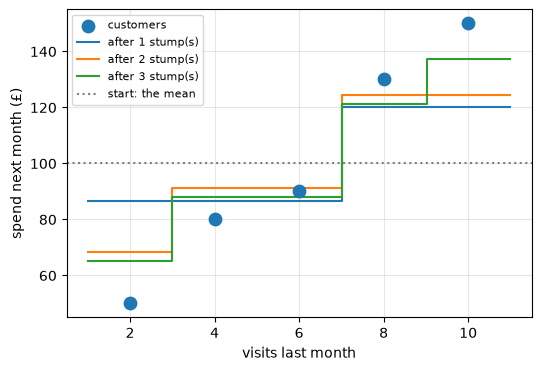

In [6]:
xs_plot = np.linspace(1, 11, 200).reshape(-1, 1)
plt.figure(figsize=(6, 4))
plt.scatter(x, y, s=80, zorder=3, label="customers")
for m, curve in enumerate(gbr.staged_predict(xs_plot), start=1):
    plt.step(xs_plot.ravel(), curve, where="mid", label=f"after {m} stump(s)")
plt.axhline(y.mean(), color="gray", linestyle=":", label="start: the mean")
plt.xlabel("visits last month"); plt.ylabel("spend next month (£)")
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()

Each step function is the running total: mean + ½·stump₁ + ½·stump₂ + ½·stump₃. With more rounds the staircase hugs the points more and more closely.

## 5. AdaBoost: re-weighting mistakes

AdaBoost is boosting for classification with a different mechanism. Six customers, a stump that gets two of them wrong. All weights start equal.

In [7]:
weights = np.full(6, 1 / 6)
wrong = np.array([0, 0, 1, 0, 1, 0], dtype=bool)        # the stump misclassifies rows 2 and 4

eps = weights[wrong].sum()                               # weighted error
alpha = 0.5 * np.log((1 - eps) / eps)                    # this stump's vote
new_w = weights * np.exp(np.where(wrong, alpha, -alpha))
new_w = new_w / new_w.sum()                              # renormalise
print(f"weighted error {eps:.3f}, alpha {alpha:.3f}")
print("old weights:", weights.round(3))
print("new weights:", new_w.round(3))

weighted error 0.333, alpha 0.347
old weights: [0.167 0.167 0.167 0.167 0.167 0.167]
new weights: [0.125 0.125 0.25  0.125 0.25  0.125]


The two misclassified customers now carry **half of all the weight** between them. The next stump is forced to get them right. That is AdaBoost's whole idea.

## 6. Gradient boosting on ShopWave churn

For classification, `GradientBoostingClassifier` fits each tree to the gradient of the log-loss (03.4) instead of plain residuals, but the loop is the same.

In [8]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]
cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

def cv_auc(model):
    """Mean 5-fold cross-validated AUC on the training customers."""
    return cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc").mean()

def test_auc(model):
    """Fit on all training customers, score AUC on the held-out test customers."""
    model.fit(X_train, y_train)
    return roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

print(f"Benchmark logistic regression: CV AUC {cv_auc(logreg):.3f}, test AUC {test_auc(logreg):.3f}")

Benchmark logistic regression: CV AUC 0.740, test AUC 0.741


In [10]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(random_state=42)          # 100 trees, depth 3, learning rate 0.1
print(f"gradient boosting: CV AUC {cv_auc(gb):.3f}, test AUC {test_auc(gb):.3f}")

gradient boosting: CV AUC 0.730, test AUC 0.727


### The learning rate at work

`staged_predict_proba` gives the prediction after 1, 2, …, 500 trees, so we can watch test AUC round by round. This is for understanding only: choosing the number of rounds by looking at the *test* set would be cheating. 05.4 does it properly with a validation set.

learning rate 0.3: peak test AUC 0.739 at round 6, after 500 rounds 0.666


learning rate 0.1: peak test AUC 0.740 at round 15, after 500 rounds 0.704


learning rate 0.03: peak test AUC 0.741 at round 51, after 500 rounds 0.724


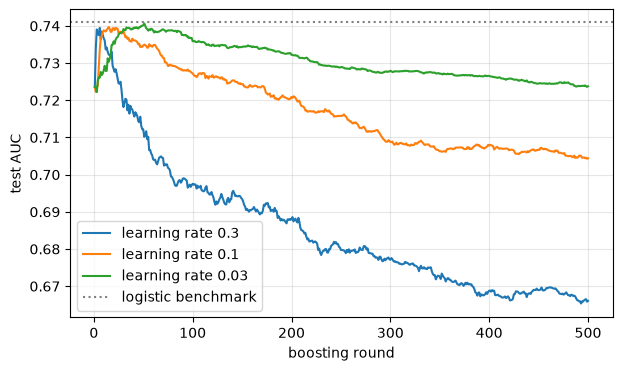

In [11]:
from sklearn.ensemble import GradientBoostingClassifier

def staged_test_auc(lr, n=500):
    gb = GradientBoostingClassifier(n_estimators=n, learning_rate=lr, max_depth=3, random_state=42)
    gb.fit(X_train, y_train)
    return [roc_auc_score(y_test, p[:, 1]) for p in gb.staged_predict_proba(X_test)]

plt.figure(figsize=(7, 4))
for lr in [0.3, 0.1, 0.03]:
    curve = staged_test_auc(lr)
    best = int(np.argmax(curve)) + 1
    print(f"learning rate {lr}: peak test AUC {max(curve):.3f} at round {best}, after 500 rounds {curve[-1]:.3f}")
    plt.plot(range(1, 501), curve, label=f"learning rate {lr}")
plt.axhline(0.741, color="gray", linestyle=":", label="logistic benchmark")
plt.xlabel("boosting round"); plt.ylabel("test AUC"); plt.legend(); plt.grid(alpha=.3); plt.show()

A big learning rate peaks within a few dozen rounds and then **declines**: the later trees fit noise. A small one climbs slowly and holds up much longer. Unlike a random forest, more boosting rounds *can* hurt.

## Quiz answers

1. The **residuals** (more generally, the negative gradient of the loss): what the ensemble built so far still gets wrong.
2. It scales each tree's contribution. Smaller = more cautious steps, usually better generalisation, but more trees and more training time.
3. Each tree approximates the negative **gradient** of the loss with respect to the current predictions, so adding it is a step of gradient descent in function space. For squared error that gradient is just the residual.
4. No. Boosting keeps reducing training error and eventually fits noise; test performance peaks and then declines. Use a small learning rate and early stopping.
5. It increases the weights of misclassified rows (×$e^{\alpha}$) and decreases the weights of correct ones (×$e^{-\alpha}$), so the next stump's weighted error is dominated by the hard rows.

**Next:** [05.4 XGBoost, LightGBM and CatBoost](../04-xgboost-lightgbm/)